# Which number carries the city head's slide, and how many drivers does the evening peak need?

**Week 4, Tuesday, the day's one notebook (chapters 1 and 4).** Uber, Hyderabad, the driver app's
peak-hour earnings guarantee, one day on. The city head takes the redesign to the Thursday city review
on one slide, in five minutes, with the driver-operations lead, the marketing lead and the finance
partner in the room. The number the slide must explain first: gross bookings per peak online hour fell
from Rs 314 in the six weeks before the launch (31 August 2026) to Rs 260 in the six weeks after, while
the average peak fare stayed at Rs 165. In the afternoon the city head adds a smaller ask: roughly how
many drivers must be online at the weekday evening peak to keep the median rider wait under five
minutes, sized without a dataset.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**What Monday found.** Peak online hours rose 24 percent while completed peak trips rose 3 percent, so
trips per peak online hour fell from 1.90 to 1.58, and 61 percent of the Rs 1.9 crore top-up went to
driver-weeks that accepted fewer than half the requests offered to them.

**Who needs the answer.** The city head, whose one slide decides whether the scheme is redesigned or
extended; a slide that quotes the wrong denominator hands each of the three roles a number to argue
with, and the city keeps paying for idle hours.

**The questions on the way.**

1. What do the twelve rows say when the same rupees are read three ways?
2. Which way does each read go over all the driver-weeks, and why does the per-driver-week read rise?
3. Is the fall in rupees per hour all trips, or some of it fare?
4. What does the twelve-week chart look like before and after the makeover?
5. How many drivers must be online at the evening peak, and which assumption moves the answer most?
6. Is the estimate sane against the case's own data and a published number?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

rows = pd.read_csv("../data/C2_W04_D02_twelve_rows_STUDENT.csv")    # six drivers, two weeks
weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")  # the city, week by week
print(len(rows), "driver-weeks in the twelve rows;", len(weeks), "weeks in the city table")

12 driver-weeks in the twelve rows; 12 weeks in the city table


## What do the twelve rows say when the same rupees are read three ways?

Each row is one driver in one week: peak online hours, peak trips and the gross bookings those trips
brought in. Gross bookings are what riders paid for the trips, before Uber's share and before any
top-up. The same rupees can be divided by three things: the hours online, the driver-weeks, or the
trips. The cell sums each column per window and divides three times, exactly as the board did.

**Predict before you run.** Which read falls most on the twelve rows?

- a) Rupees per peak online hour falls most, and rupees per trip holds
- b) Rupees per driver-week falls most, and rupees per trip rises
- c) All three fall by about the same share
- d) Rupees per trip falls most, and rupees per driver-week holds

In [2]:
t = rows.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs"]].sum()
t["driver_weeks"] = rows.groupby("window").size()
t["rs_per_hour"] = (t.peak_bookings_rs / t.peak_online_hours).round(1)
t["rs_per_driver_week"] = t.peak_bookings_rs / t.driver_weeks
t["rs_per_trip"] = t.peak_bookings_rs / t.peak_trips
t = t.loc[["before", "after"]]
print(t[["peak_online_hours", "peak_trips", "peak_bookings_rs", "rs_per_hour", "rs_per_driver_week", "rs_per_trip"]])
check("hand count: Rs 313.5 and Rs 196.2 per hour", list(t.rs_per_hour) == [313.5, 196.2])
check("hand count: Rs 3,135 and Rs 2,420 per driver-week", list(t.rs_per_driver_week) == [3135, 2420])

        peak_online_hours  peak_trips  peak_bookings_rs  rs_per_hour  \
window                                                                 
before                 60         114             18810        313.5   
after                  74          88             14520        196.2   

        rs_per_driver_week  rs_per_trip  
window                                   
before              3135.0        165.0  
after               2420.0        165.0  
PASS hand count: Rs 313.5 and Rs 196.2 per hour
PASS hand count: Rs 3,135 and Rs 2,420 per driver-week


**What happened.** The answer is a. Per peak online hour the six drivers fell from Rs 313.5 to
Rs 196.2, down 37 percent; per driver-week from Rs 3,135 to Rs 2,420, down 23 percent; per trip they held
at Rs 165, because each trip pays its fare whatever else happens. Three honest divisions of the same
rupees gave three sizes of change, so a slide that says "bookings fell" without its denominator has
said nothing a role cannot argue with.

## Which way does each read go over all the driver-weeks, and why does the per-driver-week read rise?

The city table holds every week's totals. An active driver-week is one driver with a row in Monday's
`driver_weeks` table that week, whether or not the driver is enrolled in the guarantee, so it counts
drivers who used the app, never sign-ups.

**Predict before you run.** Over the six weeks before and the six weeks after, which pair holds?

- a) Rupees per hour falls sharply, and rupees per active driver-week falls too
- b) Rupees per hour falls sharply, and rupees per active driver-week rises slightly
- c) Rupees per hour holds, and rupees per active driver-week falls
- d) Both read nearly flat

In [3]:
w = weeks.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs", "active_driver_weeks"]].sum()
w = w.loc[["before", "after"]]
w["rs_per_hour"] = w.peak_bookings_rs / w.peak_online_hours
w["rs_per_driver_week"] = w.peak_bookings_rs / w.active_driver_weeks
w["rs_per_trip"] = w.peak_bookings_rs / w.peak_trips
change = (w.loc["after"] / w.loc["before"] - 1) * 100
print(w[["rs_per_hour", "rs_per_driver_week", "rs_per_trip"]].round(1))
print((change[["rs_per_hour", "rs_per_driver_week", "rs_per_trip"]]).round(1).rename("change, percent"))
check("per hour down 16.9 percent, printed as 17", round(change.rs_per_hour, 1) == -16.9)
check("per active driver-week up 0.8 percent", round(change.rs_per_driver_week, 1) == 0.8)

        rs_per_hour  rs_per_driver_week  rs_per_trip
window                                              
before        313.5              5816.5        165.0
after         260.4              5861.3        165.0
rs_per_hour          -16.9
rs_per_driver_week     0.8
rs_per_trip            0.0
Name: change, percent, dtype: float64
PASS per hour down 16.9 percent, printed as 17
PASS per active driver-week up 0.8 percent


**What happened.** The answer is b. Per peak online hour the rupees fell from Rs 313.5 to Rs 260.4,
down 17 percent. Per active driver-week they rose from Rs 5,817 to Rs 5,861, up 0.8 percent. Per trip
they stayed at Rs 165.

**The plausible wrong answer.** "Bookings per driver-week rose from Rs 5,817 to Rs 5,861, so the
guarantee is working; keep it as it is." That sentence is true to the rupee and would keep the city
paying for idle hours.

**Why it is wrong.** The per-driver-week read is bookings divided by active driver-weeks, and online
hours do not enter it. Bookings rose 3.0 percent because trips rose 3 percent at the same fare. Active
driver-weeks rose only 2.2 percent, from 6,360 to 6,500, because the 140 drivers who joined after the
launch added 140 driver-weeks between them, driving only some of the six weeks. The ratio rose 0.8
percent without any driver earning more for an hour online, while the scheme pays per online hour. The
next cell checks the three growth rates side by side.

## Is the fall in rupees per hour all trips, or some of it fare?

A second route reaches rupees per hour without dividing bookings by hours: the average fare times the
trips each online hour carried. If the two routes agree, the fall is all trips.

In [4]:
growth = change[["peak_bookings_rs", "active_driver_weeks"]].round(1)
print(growth.rename("growth, percent"))
check("bookings growth over driver-week growth gives the per-driver-week rise", round(((1 + change.peak_bookings_rs / 100)
      / (1 + change.active_driver_weeks / 100) - 1) * 100, 1) == round(change.rs_per_driver_week, 1))
fare = w.peak_bookings_rs / w.peak_trips
trips_per_hour = w.peak_trips / w.peak_online_hours
second_route = fare * trips_per_hour
print(pd.DataFrame({"fare": fare, "trips_per_hour": trips_per_hour.round(2),
                    "fare_x_trips_per_hour": second_route.round(1)}))
check("second route agrees with bookings / hours in both windows",
      ((second_route - w.rs_per_hour).abs() < 1e-9).all())

peak_bookings_rs       3.0
active_driver_weeks    2.2
Name: growth, percent, dtype: float64
PASS bookings growth over driver-week growth gives the per-driver-week rise
         fare  trips_per_hour  fare_x_trips_per_hour
window                                              
before  165.0            1.90                  313.5
after   165.0            1.58                  260.4
PASS second route agrees with bookings / hours in both windows


**What happened.** Rs 165 times 1.90 trips per hour is Rs 313.5, and Rs 165 times 1.58 is
Rs 260.4, so the two routes agree and the fare did not move: the whole fall in rupees per hour is the
fall in trips per hour that Monday found. That is the evidence line the slide stands on when the finance
partner asks whether riders paid less.

## What does the twelve-week chart look like before and after the makeover?

The cluttered version is the one dashboards send: four series in four units on one axis, two of them
divided by 20 or 100 to fit, a legend away from the lines, gridlines, and a title that names a topic.
The clear version keeps one series, the one the scheme pays per, draws the launch, labels the two
windows' values on the lines, and makes the title a sentence.

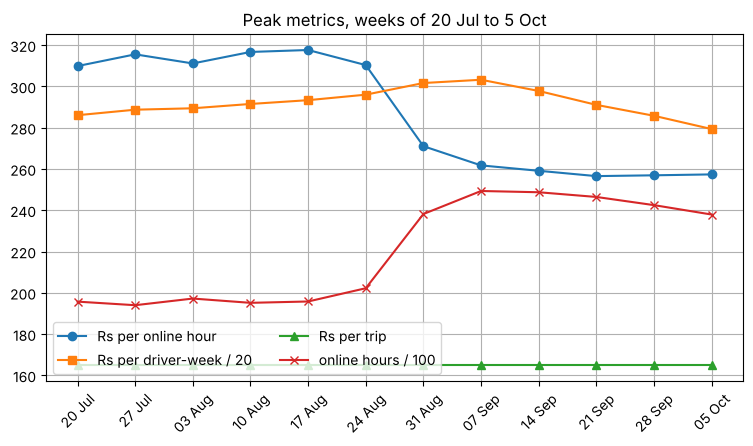

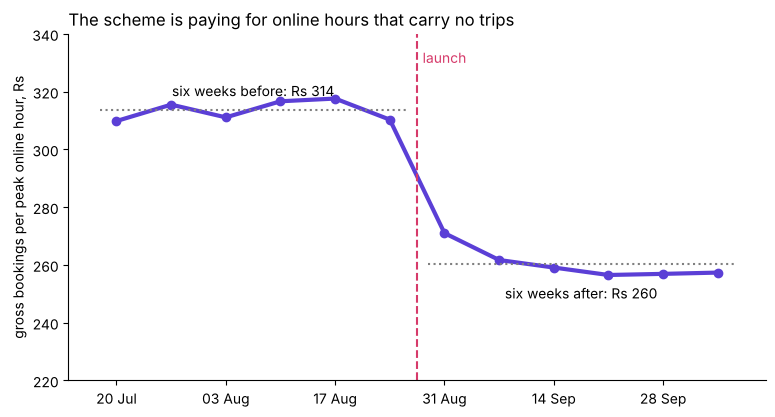

PASS every after week sits below every before week: a step at the launch, not a slow drift


In [5]:
x = range(len(weeks))
labels = pd.to_datetime(weeks.week_start).dt.strftime("%d %b")

fig, ax = plt.subplots(figsize=(9, 4.5))                      # before: everything at once
ax.plot(x, weeks.rs_per_hour, marker="o", label="Rs per online hour")
ax.plot(x, weeks.rs_per_driver_week / 20, marker="s", label="Rs per driver-week / 20")
ax.plot(x, weeks.rs_per_trip, marker="^", label="Rs per trip")
ax.plot(x, weeks.peak_online_hours / 100, marker="x", label="online hours / 100")
ax.grid(True); ax.legend(loc="lower left", ncol=2)
ax.set_xticks(list(x), labels, rotation=45); ax.set_title("Peak metrics, weeks of 20 Jul to 5 Oct")
plt.show()

before, after = w.rs_per_hour
fig, ax = plt.subplots(figsize=(9, 4.5))                      # after: one claim, one series
ax.plot(x, weeks.rs_per_hour, color="#5B3FD6", lw=3, marker="o")
ax.hlines(before, -0.3, 5.3, color="gray", ls=":"); ax.hlines(after, 5.7, 11.3, color="gray", ls=":")
ax.text(2.5, before + 5, f"six weeks before: Rs {before:.0f}", ha="center")
ax.text(8.5, after - 12, f"six weeks after: Rs {after:.0f}", ha="center")
ax.axvline(5.5, color="#D63A6A", ls="--"); ax.text(5.6, 330, "launch", color="#D63A6A")
ax.set_ylim(220, 340); ax.set_xticks(list(x)[::2], labels[::2])
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The scheme is paying for online hours that carry no trips", loc="left")
ax.set_ylabel("gross bookings per peak online hour, Rs")
plt.show()
step = weeks[weeks.window == "after"].rs_per_hour.max() < weeks[weeks.window == "before"].rs_per_hour.min()
check("every after week sits below every before week: a step at the launch, not a slow drift", step)

**What happened.** On the clear chart the eye finds the claim in a second: about Rs 314 an hour
before, about Rs 260 after, and the drop lands in the launch week, with the highest after week (Rs 271)
below the lowest before week (Rs 310). A season that ended slowly would drift; this steps. That helps
with the finance partner's monsoon objection without settling it, since last year's weeks are not in
the data.

## How many drivers must be online at the weekday evening peak, and which assumption moves the answer most?

**Clarify.** One city (the Hyderabad metro area), one platform (Uber), the three-hour weekday evening
peak, drivers online at one moment, and a median rider wait under five minutes.

**Map.** Drivers online = rider requests an hour / trips one online driver completes an hour x a buffer.
Requests an hour walk from a crowd to a count: people x the share who ride on a weekday x the share of
the day's trips in the evening window / 3 hours. Trips one online driver completes an hour are the
trips a busy driver fits in an hour x (1 - the idle share), where the idle share is the share of online
drivers with no rider at that moment. The buffer covers the busiest half hour of the window.

Every value below is an assumption said aloud, with the range it could take.

**Predict before you run.** Which assumption moves the answer most across its range?

- a) The idle share
- b) The share of people who ride on a weekday
- c) The buffer for the busiest half hour
- d) The trips a busy driver fits in an hour

requests an hour: 8,333; drivers online: 5,704
                                  lowest  highest
buffer for the busiest half hour    5500     6200
people in the city                  5100     6300
idle share                          5100     6400
share of trips in the evening       4600     6800
trips a busy driver fits an hour    4600     6800
share who ride on a weekday         2900     8600


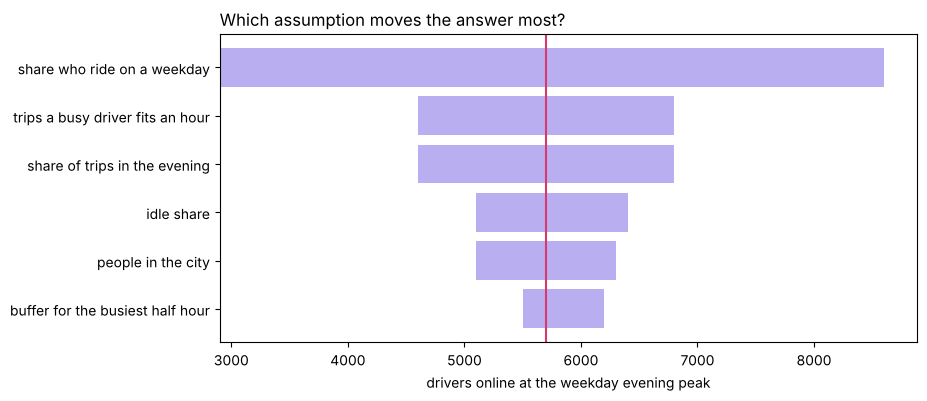

PASS about 5,700 drivers at the central values
PASS the share who ride moves the answer most


In [6]:
ledger = pd.DataFrame([            # assumption: central value, low end, high end
    ("people in the city",              1e7,   9e6,   1.1e7),
    ("share who ride on a weekday",     0.01,  0.005, 0.015),
    ("share of trips in the evening",   0.25,  0.20,  0.30),
    ("trips a busy driver fits an hour", 2.4,   2.0,   3.0),
    ("idle share",                      0.30,  0.22,  0.38),
    ("buffer for the busiest half hour", 1.15,  1.10,  1.25),
], columns=["assumption", "central", "low", "high"]).set_index("assumption")

def drivers(v):
    per_hour = v[0] * v[1] * v[2] / 3
    return per_hour / (v[3] * (1 - v[4])) * v[5]

central = drivers(list(ledger.central))
swing = {}
for i, name in enumerate(ledger.index):
    ends = []
    for end in ("low", "high"):
        v = list(ledger.central); v[i] = ledger.loc[name, end]; ends.append(drivers(v))
    swing[name] = (min(ends), max(ends))
swing = pd.DataFrame(swing, index=["lowest", "highest"]).T.round(-2).astype(int)
swing["width"] = swing.highest - swing.lowest
swing = swing.sort_values("width")
print(f"requests an hour: {1e7 * 0.01 * 0.25 / 3:,.0f}; drivers online: {central:,.0f}")
print(swing[["lowest", "highest"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(swing.index, swing.width, left=swing.lowest, color="#B9AEF0")
ax.axvline(central, color="#D63A6A"); ax.set_xlabel("drivers online at the weekday evening peak")
ax.set_title("Which assumption moves the answer most?", loc="left")
plt.show()
check("about 5,700 drivers at the central values", round(central, -2) == 5700)
check("the share who ride moves the answer most", swing.index[-1] == "share who ride on a weekday")

**What happened.** The answer is b. About 8,300 requests an hour divided by 1.68 trips per online
driver-hour (2.4 x 0.70), times 1.15, is about 5,700 drivers. Moving the ride share from 0.5 percent
to 1.5 percent moves the answer from about 2,900 to about 8,600, wider than any other assumption, so the honest
answer is "about 5,700, between about 2,900 and 8,600, and mostly a question of how many people ride".
The idle share moves it less (about 5,100 to 6,400), and it is the one assumption Monday's data shows
moving: from 0.22 to 0.38 of online hours with no trip in six weeks.

## Is the estimate sane against the case's own data and a published number?

**Validate.** Monday's tables are a slice of the city, the twelve zones the enrolled drivers work, so
their absolute count cannot check a city total. Monday's data counts peak hours on all seven days, two
three-hour windows a day, 42 hours a week, so its 2,56,556 after-window requests are about 1,018 an
hour, far below the city's 8,300. What the slice can check is the ratio in the middle of the chain:
online driver-hours behind each rider request. The published figure for Uber drivers online in
Hyderabad at the evening peak is to be found; no source holds it.

The afternoon's paired drill gets the same treatment: about 35 crore active UPI users (one in four of
India's roughly 140 crore people) times about 2 payments a day, set against NPCI's average of 802 million
a day in September 2026 (Outlook Money, 2 October 2026, checked 12 October 2026).

In [7]:
case = weeks.groupby("window")[["peak_online_hours", "rider_requests"]].sum().loc[["before", "after"]]
case["driver_hours_per_request"] = (case.peak_online_hours / case.rider_requests).round(2)
chain = 1 / (2.4 * (1 - 0.30))
print(case)
print(f"the chain puts {chain:.2f} driver-hours behind each request, before the buffer")
check("the chain sits within a third of what the case needed before the launch",
      1 < chain / case.loc["before", "driver_hours_per_request"] < 1.33)

upi_estimate = 35e7 * 2                     # people paying by UPI in a month x payments a day
npci_per_day = 802e6                        # NPCI's September 2026 average a day
month_total = 24.07e9                       # the same month's total
print(f"estimate {upi_estimate / 1e6:,.0f} million a day, {upi_estimate / npci_per_day - 1:+.0%} against NPCI")
print(f"the month over 30 days: {month_total / 30 / 1e6:,.0f} million; over 31 days: {month_total / 31 / 1e6:,.0f} million")
check("same order of magnitude as the published figure", 0.5 < upi_estimate / npci_per_day < 2)
check("the per-day figure, not the month divided by 31, is the anchor", round(month_total / 30 / 1e6) == 802)

        peak_online_hours  rider_requests  driver_hours_per_request
window                                                             
before             118000          251910                      0.47
after              146300          256556                      0.57
the chain puts 0.60 driver-hours behind each request, before the buffer
PASS the chain sits within a third of what the case needed before the launch
estimate 700 million a day, -13% against NPCI
the month over 30 days: 802 million; over 31 days: 776 million
PASS same order of magnitude as the published figure
PASS the per-day figure, not the month divided by 31, is the anchor


**What happened.** Before the launch, the case's twelve zones had 0.47 online driver-hours behind
each rider request and a median wait of 4.8 minutes; after it, 0.57. The chain puts 0.60 behind each
request before its buffer, about a quarter more than the case needed for a wait under five minutes, so
the chain errs on the generous side, and the buffer is the first factor to trim. The UPI estimate,
700 million a day, sits 13 percent below NPCI's 802 million, the same order and a little low, which points at
payments a day. Dividing September's 24.07 billion by 31 days gives 776 million and a wrong 3 percent.

**The answers, one line each.**

1. On the twelve rows the same rupees fell 37 percent per hour, 23 percent per driver-week and 0 per trip.
2. Over all driver-weeks, per hour fell 17 percent, per active driver-week rose 0.8 percent (bookings up 3.0, driver-weeks up 2.2), per trip held at Rs 165.
3. The fall is all trips: Rs 165 x 1.90 is Rs 313.5, and Rs 165 x 1.58 is Rs 260.4.
4. The clear chart carries one series, a launch line and a sentence for a title; the drop is a step at the launch.
5. About 5,700 drivers, between about 2,900 and 8,600, driven by the share of people who ride.
6. The chain's 0.60 driver-hours per request sits a quarter above the case's 0.47; the published figure is to be found.

### In the interview

**[S] Present this recommendation to a non-technical leader in two minutes.** Open on the claim ("the
scheme is paying for online hours that carry no trips"), give one number with its denominator (Rs 314 to
Rs 260 per peak online hour), say the caveat (the monsoon ended inside the window), and end on the action
with its cost (pay per completed peak trip with an acceptance floor; Rs 58 lakh to Rs 93 lakh back over six
weeks if a fifth to a half of the idle drivers start accepting).

**[S] How many drivers must be online at the evening peak?** Clarify the city, the window, the unit
(online at one moment) and the wait target; map the chain; say each assumption aloud; give the range and
the factor that drives it; validate the ratio against data you trust and name the figure still to be found.

**The AI-company variant.** A coding assistant's dashboard reports suggestions accepted per developer-week.
The same trap waits: the denominator can grow, or accepted text can be deleted before the next commit. The
read that matches what the product promises is suggested text still present at the next commit, per
active developer-week, with acceptance kept as a leading input.